## **COFFEE SHOP ANALYSIS**

## Business Problem

The coffee shop collects sales data however the owner lacks a clear understanding of the shop's product performance, customer purchasing patterns and revenue trends.

The objective of this project is to analyse sales transactions to identify which products perform best, when it experiences highest and lowest demand, how sales patterns change over time and how historical pricing relates to sales performance.

## Project Objectives

1. Evaluate product popularity and revenue contribution.
2. Identify periods of higher demand by hour and weekday.
3. Analyse monthly sales trends and changes in product popularity.
4. Investigate historical selling prices and their relationship with sales volume and revenue.
5. Develop data-driven recommendations to support business decisions.

## Dataset Overview

The dataset contains 3,547 records covering March 2024 to March 2025. Each row represents an individual drink sold.

The dataset includes information about the sale date, time, drink type, selling price and payment method.

The currency of the selling prices is not specified in the dataset. Therefore, sales figures are presented using the original values without assigning a currency.

## Expected Outcome

Provide an overview of the coffee shop's sales performance and identify opportunities to improve product management, stock planning and operational efficiency.

In [2]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sys
import os

# Add src folder to Python path
sys.path.append(os.path.abspath(".."))

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

from utils import bootcampviztools as bt
from utils.bootcampviztools import pinta_distribucion_categoricas, plot_categorical_numerical_relationship, plot_categorical_relationship_fin, plot_multiple_boxplots, plot_combined_graphs, plot_grouped_boxplots,plot_grouped_histograms, scatter_plots_agrupados

#### DATA CLEANING

In [3]:
# Load dataset
# Read csv
df_coffee = pd.read_csv("../data/coffee_sales.csv")

In [4]:
# Create copy 
df = df_coffee.copy()

In [5]:
# Inspect columns
df.head()

,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,10:15:50.520000
1,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:19:22.539000
2,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:20:18.089000
3,13,card,28.9,Americano,Afternoon,Fri,Mar,5,3,2024-03-01,13:46:33.006000
4,13,card,38.7,Latte,Afternoon,Fri,Mar,5,3,2024-03-01,13:48:14.626000


In [6]:
# Check info of dataframe to see column names, nulls, data types etc
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3547 entries, 0 to 3546
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hour_of_day  3547 non-null   int64  
 1   cash_type    3547 non-null   str    
 2   money        3547 non-null   float64
 3   coffee_name  3547 non-null   str    
 4   Time_of_Day  3547 non-null   str    
 5   Weekday      3547 non-null   str    
 6   Month_name   3547 non-null   str    
 7   Weekdaysort  3547 non-null   int64  
 8   Monthsort    3547 non-null   int64  
 9   Date         3547 non-null   str    
 10  Time         3547 non-null   str    
dtypes: float64(1), int64(3), str(7)
memory usage: 304.9 KB


### Initial inspection

On initial inspection of the dataset we see the following:
- The dataset has 3547 rows each of which is a coffee transaction
- The dataset has 11 columns
- There are no null values, meaning that to begin with, there is no need to impute values
- Date and Time columns are in string format and will need to be changed into dat time format.

### Follow up actions

To follow up with the initial inspection the following actions will be taken:

- Change Date and Time columns into datetime format
- Change name of money column to sale_amount
- Change name of coffee_name column to drink_name
- Make all column headers lowercase
- Change name of weekdaysort and monthsort to weekday_num and month_num
- Change name of cash type column to payment_type

In [7]:
# Change column names
df = df.rename(columns={
    'money': 'sale_amount',
    'cash_type': 'payment_type',
    'coffee_name': 'drink_type',
    'Month_name' : 'month',
    'Weekdaysort': 'weekday_num',
    'Monthsort': 'month_num'
})

In [8]:
# Change column names to lowercase

df.columns = df.columns.str.strip().str.lower()

In [9]:
# Change date into dattime format and change time into datetime format as well

df['date'] = pd.to_datetime(df['date'])
df['time'] = pd.to_datetime(df['time'], format='mixed').dt.time

# remove microseconds from time column
df['time'] = df['time'].apply(lambda t: t.replace(microsecond=0))

### Next steps

The next steps will include validating the data. 
- Check for duplicates
- check for unique values
- check describe for numeric values to see if there are any strange numeric values

In [10]:
# check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [11]:
# Check unique values of all columns excluding date and time 
for col in df.columns:
    if col not in ["date","time"]:
        print()
        print(f"{col}\n {df[col].unique()}")


hour_of_day
 [10 12 13 15 16 18 19 11 14 17  9 20  8 22  7 21  6]

payment_type
 <StringArray>
['card']
Length: 1, dtype: str

sale_amount
 [38.7  28.9  33.8  24.   32.82 37.72 27.92 23.02 18.12 35.76 30.86 25.96
 21.06]

drink_type
 <StringArray>
[              'Latte',       'Hot Chocolate',           'Americano',
 'Americano with Milk',               'Cocoa',             'Cortado',
            'Espresso',          'Cappuccino']
Length: 8, dtype: str

time_of_day
 <StringArray>
['Morning', 'Afternoon', 'Night']
Length: 3, dtype: str

weekday
 <StringArray>
['Fri', 'Sat', 'Sun', 'Mon', 'Tue', 'Wed', 'Thu']
Length: 7, dtype: str

month
 <StringArray>
['Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan',
 'Feb']
Length: 12, dtype: str

weekday_num
 [5 6 7 1 2 3 4]

month_num
 [ 3  4  5  6  7  8  9 10 11 12  1  2]


In [12]:
# Groupby to get a better look at where the various sale amounts come from.
df.groupby("drink_type")["sale_amount"].unique()

drink_type
Americano              [28.9, 27.92, 23.02, 25.96]
Americano with Milk    [33.8, 32.82, 27.92, 30.86]
Cappuccino             [38.7, 37.72, 32.82, 35.76]
Cocoa                  [38.7, 37.72, 32.82, 35.76]
Cortado                [28.9, 27.92, 23.02, 25.96]
Espresso               [24.0, 23.02, 18.12, 21.06]
Hot Chocolate          [38.7, 37.72, 32.82, 35.76]
Latte                  [38.7, 37.72, 32.82, 35.76]
Name: sale_amount, dtype: object

It appears that the amounts come from price changes for the drinks. All price changes for all the drinks follow the same pattern showing that these price differences come from pricing strategy. Further investigation will show that the price changes are not random.

In [13]:
# Check describe for numeric values.
df.describe()

,hour_of_day,sale_amount,weekday_num,month_num,date
count,3547.000000,3547.000000,3547.000000,3547.000000,3547
mean,14.185791,31.645216,3.845785,6.453905,2024-10-04 17:34:43.676346
min,6.000000,18.120000,1.000000,1.000000,2024-03-01 00:00:00
25%,10.000000,27.920000,2.000000,3.000000,2024-07-17 12:00:00
50%,14.000000,32.820000,4.000000,7.000000,2024-10-10 00:00:00
75%,18.000000,35.760000,6.000000,10.000000,2025-01-11 00:00:00
max,22.000000,38.700000,7.000000,12.000000,2025-03-23 00:00:00
std,4.234010,4.877754,1.971501,3.500754,NaN


#### FEATURE ENGINEERING

The following features will be created:
- is_weekend: To see any patterns and difference with the weekend

In [14]:
# create is_weekend column from weekday_num column
df['is_weekend'] = df['weekday_num'].isin([6, 7]).astype(int)

## ANALYSIS

In [15]:
# Show total sales per drink type
product_sales = (
    df.groupby('drink_type')
    .size()
    .reset_index(name='total_sales')
    .sort_values('total_sales', ascending=False)
)

product_sales

,drink_type,total_sales
1,Americano with Milk,809
7,Latte,757
0,Americano,564
2,Cappuccino,486
4,Cortado,287
6,Hot Chocolate,276
3,Cocoa,239
5,Espresso,129


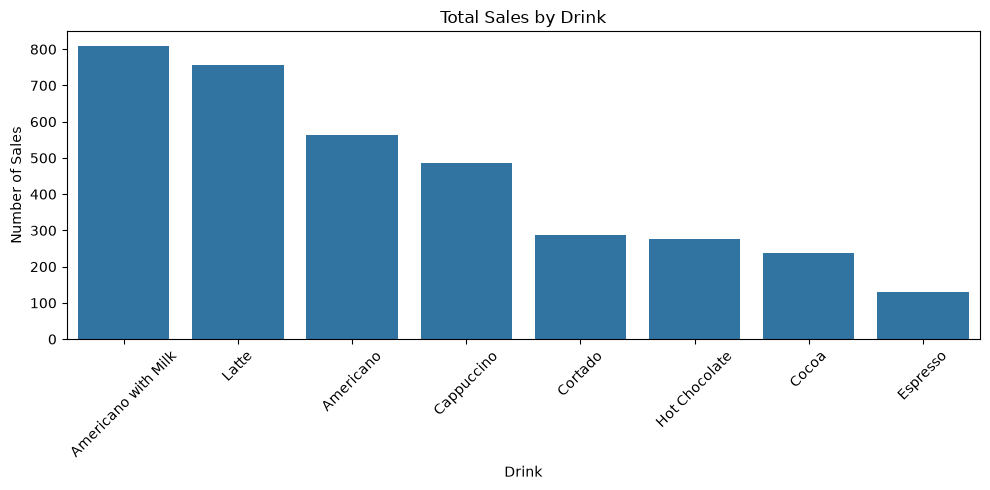

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=product_sales,
    x='drink_type',
    y='total_sales'
)

plt.title('Total Sales by Drink')
plt.xlabel('Drink')
plt.ylabel('Number of Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
# Add percentage column to see what percentage of all sales is made up by each drink type
product_sales['sales_percentage'] = (
    product_sales['total_sales'] /
    product_sales['total_sales'].sum()
) * 100

product_sales

,drink_type,total_sales,sales_percentage
1,Americano with Milk,809,22.808007
7,Latte,757,21.341979
0,Americano,564,15.900761
2,Cappuccino,486,13.701720
4,Cortado,287,8.091345
6,Hot Chocolate,276,7.781224
3,Cocoa,239,6.738089
5,Espresso,129,3.636876


*INSIGHT*
* We see that Americano with Milk is the most popular drink, followed closely by Latte and then Americano and Cappuccino, with the remaining drinks making up a much smaller percentage of total sales.

In [18]:
# Now we show the total revenue per drink type
product_revenue = (
    df.groupby('drink_type')
    .agg(
        total_sales=('sale_amount', 'count'),
        total_revenue=('sale_amount', 'sum'),
        average_sale_value=('sale_amount', 'mean')
    )
    .reset_index()
    .sort_values('total_revenue', ascending=False)
)

product_revenue

,drink_type,total_sales,total_revenue,average_sale_value
7,Latte,757,26875.30,35.502378
1,Americano with Milk,809,24751.12,30.594710
2,Cappuccino,486,17439.14,35.883004
0,Americano,564,14650.26,25.975638
6,Hot Chocolate,276,9933.46,35.990797
3,Cocoa,239,8521.16,35.653389
4,Cortado,287,7384.86,25.731220
5,Espresso,129,2690.28,20.854884


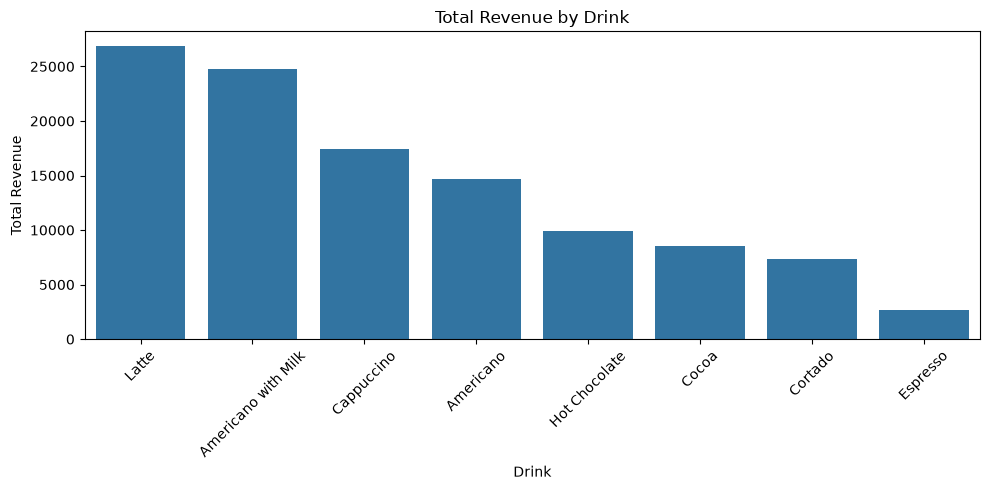

In [19]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=product_revenue,
    x='drink_type',
    y='total_revenue'
)

plt.title('Total Revenue by Drink')
plt.xlabel('Drink')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# Calculate the revenue percentage of each drink type
product_revenue['revenue_percentage'] = (
    product_revenue['total_revenue'] /
    product_revenue['total_revenue'].sum()
) * 100

product_revenue.sort_values(
    'revenue_percentage',
    ascending=False
)

,drink_type,total_sales,total_revenue,average_sale_value,revenue_percentage
7,Latte,757,26875.30,35.502378,23.943304
1,Americano with Milk,809,24751.12,30.594710,22.050864
2,Cappuccino,486,17439.14,35.883004,15.536594
0,Americano,564,14650.26,25.975638,13.051971
6,Hot Chocolate,276,9933.46,35.990797,8.849756
3,Cocoa,239,8521.16,35.653389,7.591533
4,Cortado,287,7384.86,25.731220,6.579199
5,Espresso,129,2690.28,20.854884,2.396780


*INSIGHT*
* We see that although Americano with Milk has the highest total sales, Latte is the drink that generates the highest revenue. 
* We also see that Cappuccino generates more revenue than Americano even though Americano has more total sales.

In [21]:
# Show total sales by hour of day
hourly_daily_sales= (
    df.groupby('hour_of_day')
    .agg(
        total_sales=('sale_amount', 'count'),
        
    )
    .reset_index()
)

hourly_daily_sales

,hour_of_day,total_sales
0,6,5
1,7,88
2,8,235
3,9,242
4,10,328
5,11,283
6,12,241
7,13,225
8,14,225
9,15,236


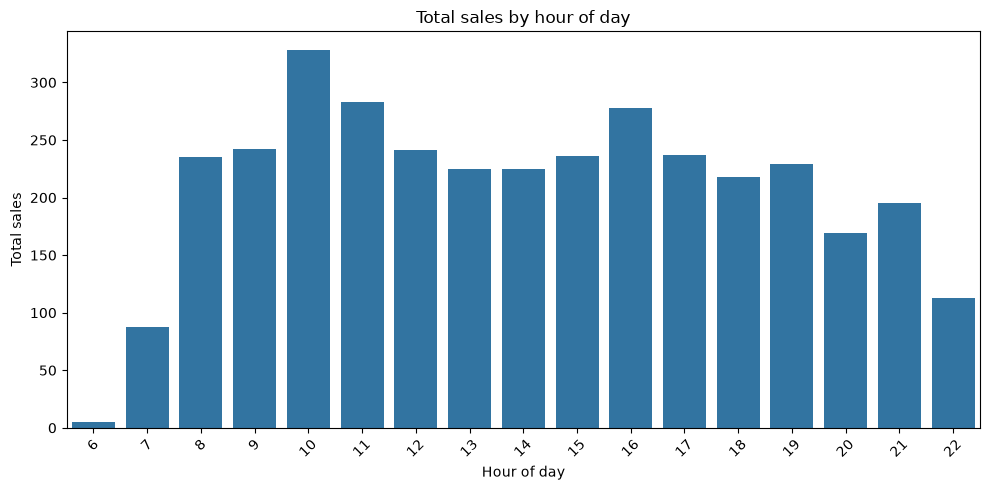

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=hourly_daily_sales,
    x='hour_of_day',
    y='total_sales'
)

plt.title('Total sales by hour of day')
plt.xlabel('Hour of day')
plt.ylabel('Total sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*INSIGHT*
* Very few sales at 06:00
* Sales start to increase rapidly after 07:00
* Peaks in sales appear to occur at 10:00 am with another peak in sales occuring in the afternoon at 16:00
* Apart from sales peaks, sales appear to remain stable from 08:00 until 19:00
* After 19:00 sales begin to drop

In [23]:
# Check total sales by weekday
weekday_sales = (
    df.groupby('weekday')
    .size()
    .reset_index(name='total_sales')
    .sort_values("total_sales",ascending=False)
)

weekday_sales

,weekday,total_sales
5,Tue,572
1,Mon,544
0,Fri,532
4,Thu,510
6,Wed,500
2,Sat,470
3,Sun,419


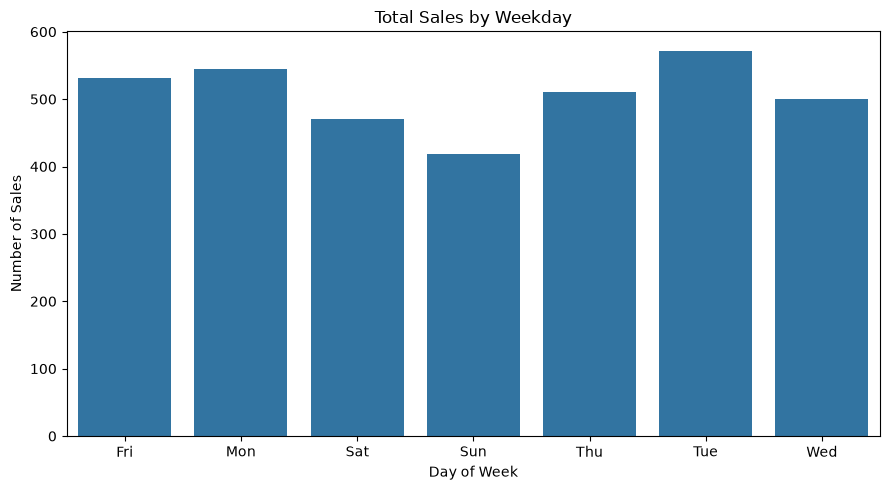

In [24]:
# Display chart for sales by weekday
plt.figure(figsize=(9, 5))

sns.barplot(
    data=weekday_sales,
    x='weekday',
    y='total_sales',
    order=sorted(weekday_sales['weekday'].unique()),
)

plt.title('Total Sales by Weekday')
plt.xlabel('Day of Week')
plt.ylabel('Number of Sales')
plt.tight_layout()
plt.show()

*INSIGHT*
* The weekday sales analysis shows that Tuesday is the day with the highest sales volume, whilst Sunday has the lowest sales volume.
* Overall weekdays appear to generate more sales than weekends.

In [25]:
# Investigate monthly sales performance

monthly_performance = (
    df.groupby(df['date'].dt.to_period('M'))
    .agg(
        total_sales=('sale_amount', 'count'),
        total_revenue=('sale_amount', 'sum')
    )
    .reset_index()
)

monthly_performance['date'] = (
    monthly_performance['date'].astype(str)
)

monthly_performance

,date,total_sales,total_revenue
0,2024-03,175,5905.20
1,2024-04,168,5719.56
2,2024-05,241,8164.42
3,2024-06,223,7617.76
4,2024-07,237,6915.94
5,2024-08,272,7613.84
6,2024-09,344,9988.64
7,2024-10,426,13891.16
8,2024-11,259,8590.54
9,2024-12,259,8237.74


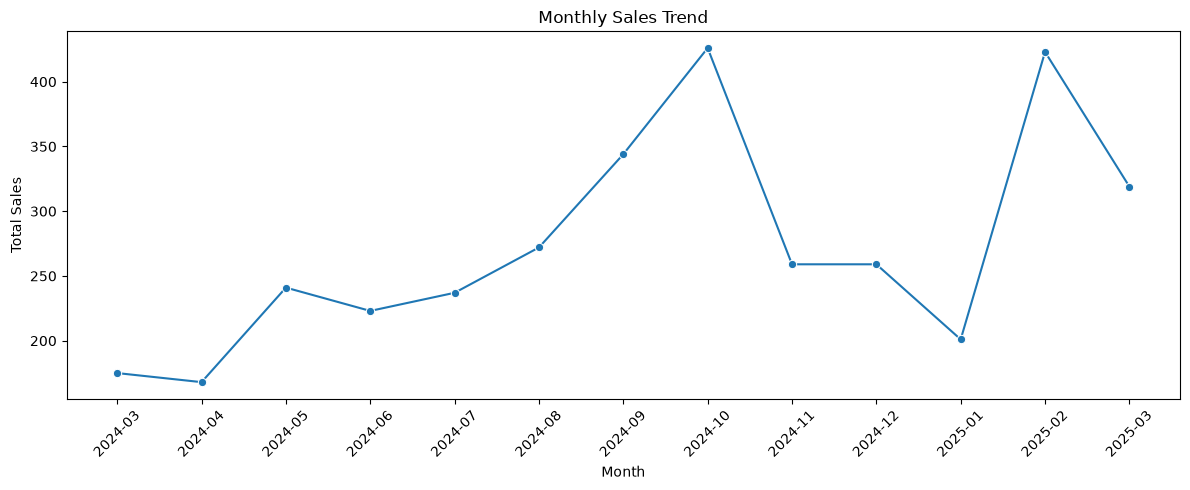

In [26]:
# Display chart for monthly sales performance

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_performance,
    x='date',
    y='total_sales',
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

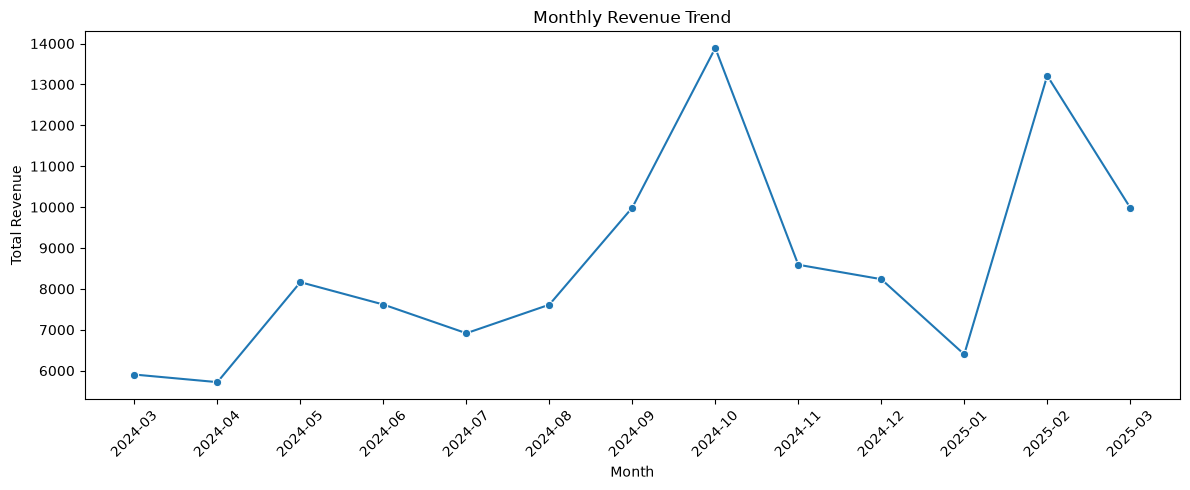

In [27]:
# Display the chart for monthly revenue trend

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_performance,
    x='date',
    y='total_revenue',
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*INSIGHT*

* We see that there was strog growth between July and October 2024 where sales increased from 237 in July to 426 in October. An increase of around 80%.
* Thereafter sales dropped considerably in November and dropped again in January
* February brought about an increase in sales of more than double that of January.

* We notice that the sales and revenue charts are very similar, indicating that changes in revenue are largely associated with changes in sales volume
* However revenue can be affected by changes in selling price and the mix of drinks purchased. As we can see October and February have similar total sales, however revenue in October, is quite a lot higher than February

In [28]:
# Show table of sales per drink per month
monthly_drink_sales = (
    df.groupby([
        df['date'].dt.to_period('M'),
        'drink_type'
    ])
    .size()
    .unstack(fill_value=0)
)

monthly_drink_sales

drink_type,Americano,Americano with Milk,Cappuccino,Cocoa,Cortado,Espresso,Hot Chocolate,Latte
date,,,,,,,,
2024-03,32,30,15,6,28,9,20,35
2024-04,33,38,36,4,16,4,10,27
2024-05,40,54,52,8,17,7,13,50
2024-06,14,66,46,4,19,10,14,50
2024-07,36,65,32,9,14,14,11,56
2024-08,37,72,34,11,40,14,6,58
2024-09,32,104,41,9,41,12,11,94
2024-10,44,82,44,32,34,12,58,120
2024-11,25,52,26,35,13,3,37,68


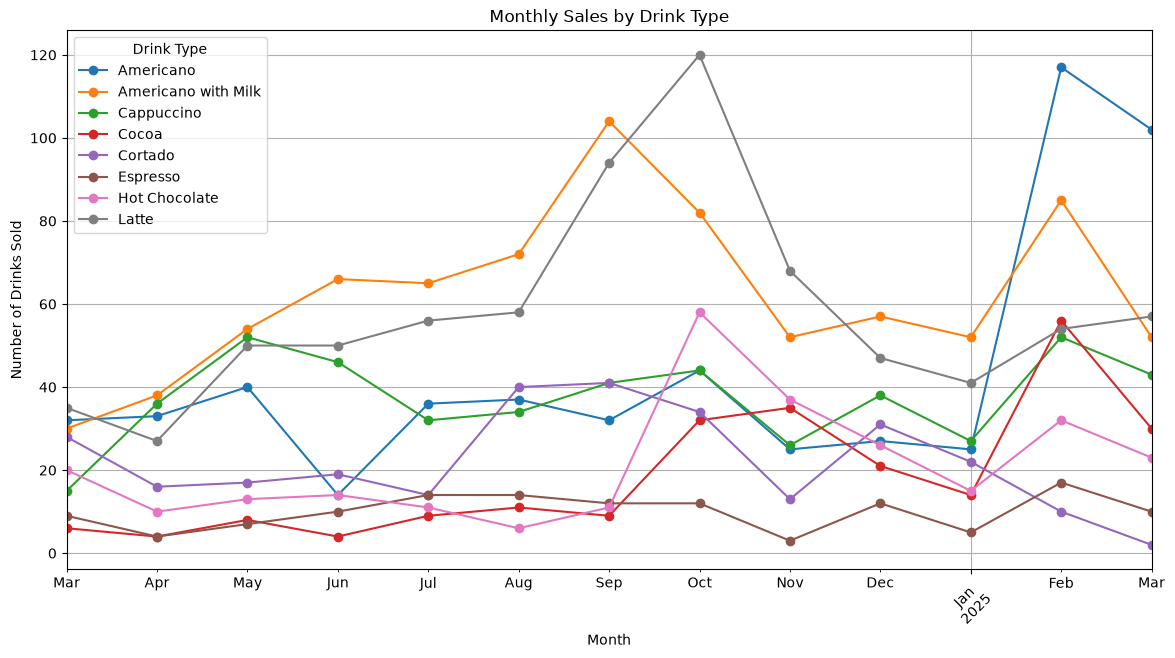

In [29]:
# Display chart of sales per drink per month
monthly_drink_sales.plot(
    figsize=(14, 7),
    marker='o'
)

plt.title('Monthly Sales by Drink Type')
plt.xlabel('Month')
plt.ylabel('Number of Drinks Sold')
plt.xticks(rotation=45)
plt.legend(title='Drink Type')
plt.grid(True)
plt.show()

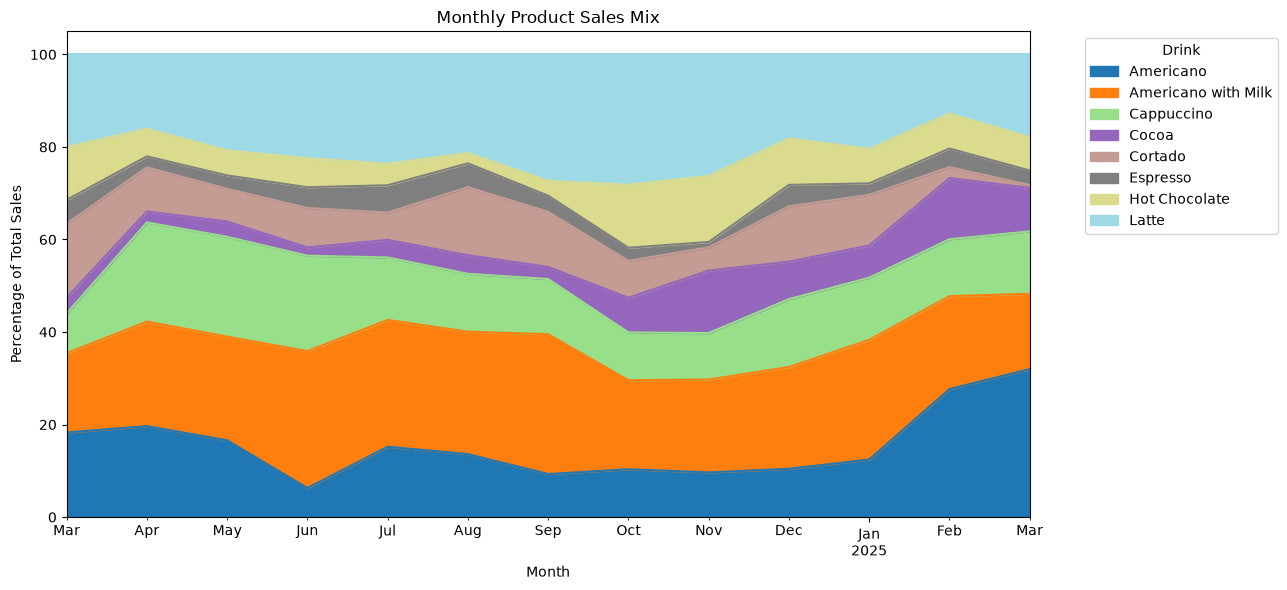

In [30]:
# Show stacked area chart for monthly sales per drink for better visual 

monthly_sales_percentage = (
    monthly_drink_sales.div(
        monthly_drink_sales.sum(axis=1),
        axis=0
    ) * 100
)

monthly_sales_percentage.plot(
    kind='area',
    stacked=True,
    figsize=(13, 6),
    colormap='tab20'
)

plt.title('Monthly Product Sales Mix')
plt.xlabel('Month')
plt.ylabel('Percentage of Total Sales')
plt.legend(
    title='Drink',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

*INSIGHT*

* In this chart we can clearly see that the differences in revenue of October and February comes from the different sales totals of different drinks. In October, sales volume is dominated by Latte and in February sales volume is dominated by Americano. As Latte generates higher revenue than Americano, this can explain the difference in revenue even though the number of sales is similar.
* It is also clear that the product sales mix changes over time, indicating that the popularity of individual drinks was not constant throughout the observation period.

In [31]:
# create pricing history table

price_history = (
    df.groupby(["drink_type","sale_amount"])
    .agg(
        first_date=("date","min"),
        last_date = ("date","max"),
        transactions = ("date", "count")
    )
    .reset_index()
    .sort_values(["drink_type","first_date"])
    )

price_history

,drink_type,sale_amount,first_date,last_date,transactions
3,Americano,28.90,2024-03-01,2024-04-20,53
2,Americano,27.92,2024-04-21,2024-07-05,72
0,Americano,23.02,2024-07-08,2024-09-27,98
1,Americano,25.96,2024-09-29,2025-03-23,341
7,Americano with Milk,33.80,2024-03-01,2024-04-20,51
6,Americano with Milk,32.82,2024-04-20,2024-07-05,147
4,Americano with Milk,27.92,2024-07-06,2024-09-28,222
5,Americano with Milk,30.86,2024-09-28,2025-03-22,389
11,Cappuccino,38.70,2024-03-06,2024-04-20,39
10,Cappuccino,37.72,2024-04-20,2024-07-05,116


In [32]:
# add days_active column to compare changes in sales at different prices

price_history['days_active'] = (
    price_history['last_date'] -
    price_history['first_date']
).dt.days + 1

# Calculate average daily sales

price_history['avg_daily_sales'] = (
    price_history['transactions'] /
    price_history['days_active']
)

# Show avg daily sales

price_history[
    ['drink_type', 'sale_amount', 'days_active',
     'transactions', 'avg_daily_sales']
]

,drink_type,sale_amount,days_active,transactions,avg_daily_sales
3,Americano,28.90,51,53,1.039216
2,Americano,27.92,76,72,0.947368
0,Americano,23.02,82,98,1.195122
1,Americano,25.96,176,341,1.937500
7,Americano with Milk,33.80,51,51,1.000000
6,Americano with Milk,32.82,77,147,1.909091
4,Americano with Milk,27.92,85,222,2.611765
5,Americano with Milk,30.86,176,389,2.210227
11,Cappuccino,38.70,46,39,0.847826
10,Cappuccino,37.72,77,116,1.506494


In [33]:
# Calculate average revenue per day of drinks

price_analysis = price_history.copy()

price_analysis['total_revenue'] = (
    price_analysis['sale_amount'] *
    price_analysis['transactions']
)

price_analysis['revenue_per_day'] = (
    price_analysis['total_revenue'] /
    price_analysis['days_active']
)

price_analysis

,drink_type,sale_amount,first_date,last_date,transactions,days_active,avg_daily_sales,total_revenue,revenue_per_day
3,Americano,28.90,2024-03-01,2024-04-20,53,51,1.039216,1531.70,30.033333
2,Americano,27.92,2024-04-21,2024-07-05,72,76,0.947368,2010.24,26.450526
0,Americano,23.02,2024-07-08,2024-09-27,98,82,1.195122,2255.96,27.511707
1,Americano,25.96,2024-09-29,2025-03-23,341,176,1.937500,8852.36,50.297500
7,Americano with Milk,33.80,2024-03-01,2024-04-20,51,51,1.000000,1723.80,33.800000
6,Americano with Milk,32.82,2024-04-20,2024-07-05,147,77,1.909091,4824.54,62.656364
4,Americano with Milk,27.92,2024-07-06,2024-09-28,222,85,2.611765,6198.24,72.920471
5,Americano with Milk,30.86,2024-09-28,2025-03-22,389,176,2.210227,12004.54,68.207614
11,Cappuccino,38.70,2024-03-06,2024-04-20,39,46,0.847826,1509.30,32.810870
10,Cappuccino,37.72,2024-04-20,2024-07-05,116,77,1.506494,4375.52,56.824935


*INSIGHT*

* The analysis of the pricing does not establish that changes in pricing directly caused changes in demand, as we can see that in some drinks, the cheaper prices do not always result in higher sales volume.

# BUSINESS RECOMMENDATIONS

Based on the findings from the analysis, the following actions could be recommended to the owner of the coffee shop:

1. **Improve stock planning:** Prioritise stock availability for high performing drinks, particularly Americano with Milk, Latte and Cappuccino. As well as taking note of peak times, so as to ensure stocking is done before peak periods in order to be ready for the rush and maximise sales and efficiency.

2. **Review staffing requirements:** Use hourly demand patterns to investigate staffing requirements during peak periods and low periods. As well as possibly revising shop opening hours ( very few sales at 06:00 am)

3. **Investigate changes in product demand:** Examine the reasons behind significant changes in product demand, such as American and Cocoa sales in February 2025. Are these changes seasonal, results of marketing campaigns or other factors?

4. **Monitor pricing performance:** Continue to track sales volume and revenue alongside selling prices. And in order to make more informed pricing decisions and allow the business to better evaluate profitability, product costs could be incorporated.

## LIMITATIONS

- **Currency:** The dataset does not specify the currency used for selling prices. Financial figures are therefore presented using the original recorded values.
- **Profitability:** Product costs and operating expenses are unavailable, preventing the calculation of profit margins or overall profitability.
- **Customer information:** No customer identifiers are available, so individual purchasing behaviour and customer retention cannot be analysed.
- **Operating days:** The dataset does not include a confirmed calendar of opening days. Daily averages are therefore based on dates with recorded transactions.
- **Pricing analysis:** Historical price periods overlap with changes in time and potentially seasonal demand. The analysis cannot establish that price changes caused changes in sales volume.
- **Incomplete period:** March 2025 only contains data up to March 23 and should not be compared directly with complete months.

# CONCLUSION

This project analysed historical coffee shop sales data to understand product performance, purchasing patterns, revenue trends and historical pricing.

The analysis identified several important findings.

Americano with Milk was the most frequently purchased product, while Latte generated the highest total revenue. This demonstrates that the most popular product is not necessarily the largest contributor to revenue.

Demand varied throughout the day, with 10:00 recording the highest number of sales. Tuesday was the busiest weekday, while Sunday recorded the lowest sales volume. These patterns could help the business review its staffing and operational requirements.

Monthly analysis revealed considerable fluctuations in performance. October 2024 recorded the highest monthly sales, followed by a significant decline towards January 2025. February 2025 experienced a strong recovery, driven particularly by increases in Americano and Cocoa sales.

The product sales mix also changed over time, indicating that the relative popularity of individual drinks was not constant throughout the observation period.

Finally, the pricing analysis demonstrated that different products experienced different sales patterns across the recorded price periods. However, the available data does not establish that price changes caused changes in demand.

Overall, the analysis provides the coffee shop with a clearer understanding of its sales performance and identifies opportunities to improve product management, stock planning and operational efficiency.

Further analysis incorporating product costs, customer information, promotions and confirmed operating days could provide additional insight into business performance.